<a href="https://colab.research.google.com/github/xudavid715-cloud/Midterm-Project/blob/main/Econ_3916_Midterm_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 Midterm Project — Econometric Foundation

**ECON 3916 · Applied Data Analytics** · Topics 1-14 · 100 points · your role: Independent analyst

This is the **starter**: the structure of the project in rubric order. Fill the empty cells and keep every heading so the grader finds each section. The brief on Canvas has the full text of every section and the rubric. The grader reruns this notebook from the top, so every number, table and figure in your report must come from a cell here.

**🛑 This project is entirely NO AI. Not phases one to three — all of it. No AI for the code, the analysis, the writing, or the editing. This is the one assessment in the course that establishes you can do the work unaided, and it is the one you will draw on when an interviewer asks what you built. Everything you have practised with a co-pilot, you do here alone.

## Start here

Work top to bottom. What each part of this notebook is for:

1. **Data provenance**: where the file came from. It feeds Section 1 and your README.
2. **Section 1**: load the data into a DataFrame called `df`, then run the *Section 1 self-check* cell and answer the questions under it. Do this before the **Mon 2 Nov** checkpoint.
3. **Section 2**: figures, each with a caption that states a finding.
4. **Section 3**: the OLS model, with a draft committed by **Fri 6 Nov**.
5. **Section 4**: diagnostics, only after Topic 14.
6. **Section 5**: words only.
7. **Numbers my report quotes**: last. Every number in the report must be printed there.

The brief's *Six checks before you post* list the problems that came up most often in Checkpoint 1. Read them before you settle on your controls.

## Setup

Imports only. Add any others you need here, at the top.

In [29]:
%pip install -q wooldridge

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.iolib.summary2 import summary_col
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats
from IPython.display import display, Markdown
import wooldridge as woo

pd.set_option("display.max_colwidth", None)   # show full row labels in tables
pd.set_option("display.width", 200)

SOURCE_NOTE = "Source: PSID, Mroz (1987) extract, via the wooldridge Python package."

## Data provenance

Fill these in when you download the data. They feed Section 1 and your README.

In [30]:
SOURCE_URL = "https://pypi.org/project/wooldridge/"   # dataset "mroz" in the wooldridge package
ORIGINAL_SOURCE = ("Mroz, T. (1987), Econometrica 55(4): 765-799; drawn from the "
                   "Panel Study of Income Dynamics (PSID), University of Michigan")
DOWNLOAD_DATE = "2026-10-26"  # YYYY-MM-DD
FILE_NAME = "mroz.csv"        # the file as saved in your repository's data/ folder

## Section 1: The Question and the Data (20 pts)

State the question in one sentence, and say why it matters and to whom. Describe the data as a product of measurement decisions, name the missingness mechanism (MCAR, MAR or MNAR) and defend the label. Build a summary-statistics table a reader can read without asking you a question.

1. **The question.** Among married white women in the U.S. who worked for pay in 1975, how much higher is the hourly wage associated with one more year of schooling, holding labor-market experience and mother's years of schooling constant? The outcome is the log hourly wage, so the schooling coefficient reads as an approximate percent difference. Mother's schooling is included as a confounder: family background can shape both a woman's schooling and her wage. The number of children under 6 is measured after schooling ended, so it is left out of the main model and used only as a sensitivity check (Section 3).
2. **Where the data come from.** I downloaded them on 2026-10-26 from https://pypi.org/project/wooldridge/, the wooldridge Python package. The original source is Mroz (1987), *Econometrica* 55(4), which used the Panel Study of Income Dynamics run by the University of Michigan.
3. **Its shape.** The file has 753 rows and 22 columns. One row is one person: a married white woman aged 30–60, observed for calendar year 1975. My regression uses the 428 women who worked.
4. **What is missing.** Only the hourly wage and its log have gaps. Each is missing for 325 women (43% of the sample), exactly the women who did not work. For them the wage is not an observed number that was left out: it is undefined, because there were no earnings to divide by hours. The problem is therefore one of sample selection: wages are seen only for women who entered employment, and the unobserved wage *offer* may have influenced that decision. In the MCAR/MAR/MNAR framework that is MNAR, a label that rests on an economic argument rather than on proof from the data (argued in full below).
5. **Join or reshape.** None. It is a single file already at the unit I want, one row per woman. The only preparation is restricting the regression sample to women who worked.

In [31]:
# Load the data: use the saved copy in data/ if it exists, otherwise get it from the package
os.makedirs("data", exist_ok=True)
DATA_PATH = "data/" + FILE_NAME
if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
else:
    df = woo.data("mroz")
    df.to_csv(DATA_PATH, index=False)
FILE_COLS = df.shape[1]   # columns in the file as loaded, before any variable is added

# Women who did not work have no wage: make sure it is missing, not 0
df.loc[df["inlf"] == 0, ["wage", "lwage"]] = np.nan
# Experience squared, divided by 100 so its coefficient is readable in Table 3.
# Rescaling changes no other coefficient, standard error, test or diagnostic.
df["expersq"] = df["exper"] ** 2 / 100

workers = df[df["inlf"] == 1]
nonworkers = df[df["inlf"] == 0]
print("Rows, columns:", df.shape)
print("Worked:", len(workers), "  Did not work:", len(nonworkers))
missing = df.isna().sum()
print("\nMissing values:")
print(missing[missing > 0])

# Readable names with units
LABELS = {
    "wage": "Hourly wage (1975 $)",
    "lwage": "Log hourly wage",
    "educ": "Schooling (years completed)",
    "exper": "Labor-market experience (years)",
    "kidslt6": "Children under 6 (number)",
    "motheduc": "Mother's schooling (years)",
    "age": "Age (years)",
    "kidsge6": "Children aged 6-18 (number)",
    "nwifeinc": "Family income minus her earnings ($1,000s)",
    "hours": "Hours worked in 1975",
    "inlf": "Worked for pay in 1975 (share)",
    "huseduc": "Husband's schooling (years)",
    "huswage": "Husband's hourly wage (1975 $)",
}

# Table 1: summary statistics for the regression sample (the women the model uses)
t1_vars = ["lwage", "educ", "motheduc", "exper", "kidslt6",
           "wage", "age", "kidsge6", "nwifeinc", "hours"]
table1 = workers[t1_vars].describe().T[["count", "mean", "std", "min", "50%", "max"]]
table1.columns = ["N", "Mean", "SD", "Min", "Median", "Max"]
table1["N"] = table1["N"].astype(int)
table1.index = [LABELS[v] for v in t1_vars]
print(f"\nTable 1. Summary statistics for the regression sample: {len(workers)} married white women "
      "aged 30-60 who worked for pay in 1975, PSID")
display(table1.round(2))

NWIFEINC_MIN = workers["nwifeinc"].min()
N_NWIFEINC_NEG = int((workers["nwifeinc"] < 0).sum())
note = ("Notes: The first four rows are the variables in the main model (experience squared is built from experience); "
        "children under 6 enters only the sensitivity check in column (4) of Table 3. "
        "The hourly wage is annual earnings divided by annual hours, in nominal 1975 dollars. SD = standard deviation. "
        f"The full file has {len(df)} women; the {len(nonworkers)} who did not work have no wage and are compared "
        "with these women in Table 2.")
if N_NWIFEINC_NEG > 0:
    note += (f" Family income minus her earnings is total family income less her own earnings; its minimum "
             f"({NWIFEINC_MIN:.2f}) is below zero because for {N_NWIFEINC_NEG} "
             f"{'woman' if N_NWIFEINC_NEG == 1 else 'women'}, reported family income is below reported own earnings.")
print(note + " " + SOURCE_NOTE)

# Table 2: women with and without a wage (evidence on the missingness mechanism)
t2_vars = ["educ", "exper", "age", "kidslt6", "kidsge6", "motheduc", "nwifeinc", "huseduc", "huswage"]
table2 = pd.DataFrame({
    "Wage observed (worked)": workers[t2_vars].mean(),
    "Wage missing (did not work)": nonworkers[t2_vars].mean(),
})
table2["Difference"] = table2["Wage observed (worked)"] - table2["Wage missing (did not work)"]
table2["p-value"] = [stats.ttest_ind(workers[v], nonworkers[v], equal_var=False).pvalue for v in t2_vars]
table2.index = [LABELS[v] for v in t2_vars]
print(f"\nTable 2. Means for women whose wage is observed (N = {len(workers)}) and missing (N = {len(nonworkers)})")
display(table2.round(3))
print("Notes: Difference = observed minus missing. p-value from a two-sided Welch t-test. "
      "If wages were missing completely at random (MCAR), the two groups would look alike on every row. " + SOURCE_NOTE)

Rows, columns: (753, 22)
Worked: 428   Did not work: 325

Missing values:
wage     325
lwage    325
dtype: int64

Table 1. Summary statistics for the regression sample: 428 married white women aged 30-60 who worked for pay in 1975, PSID


,N,Mean,SD,Min,Median,Max
Log hourly wage,428,1.19,0.72,-2.05,1.25,3.22
Schooling (years completed),428,12.66,2.29,5.00,12.00,17.00
Mother's schooling (years),428,9.52,3.31,0.00,10.00,17.00
Labor-market experience (years),428,13.04,8.06,0.00,12.00,38.00
Children under 6 (number),428,0.14,0.39,0.00,0.00,2.00
Hourly wage (1975 $),428,4.18,3.31,0.13,3.48,25.00
Age (years),428,41.97,7.72,30.00,42.00,60.00
Children aged 6-18 (number),428,1.35,1.32,0.00,1.00,8.00
"Family income minus her earnings ($1,000s)",428,18.94,10.59,-0.03,17.08,91.00
Hours worked in 1975,428,1302.93,776.27,12.00,1365.50,4950.00


Notes: The first four rows are the variables in the main model (experience squared is built from experience); children under 6 enters only the sensitivity check in column (4) of Table 3. The hourly wage is annual earnings divided by annual hours, in nominal 1975 dollars. SD = standard deviation. The full file has 753 women; the 325 who did not work have no wage and are compared with these women in Table 2. Family income minus her earnings is total family income less her own earnings; its minimum (-0.03) is below zero because for 1 woman, reported family income is below reported own earnings. Source: PSID, Mroz (1987) extract, via the wooldridge Python package.

Table 2. Means for women whose wage is observed (N = 428) and missing (N = 325)


,Wage observed (worked),Wage missing (did not work),Difference,p-value
Schooling (years completed),12.659,11.797,0.862,0.000
Labor-market experience (years),13.037,7.462,5.576,0.000
Age (years),41.972,43.283,-1.311,0.029
Children under 6 (number),0.140,0.366,-0.226,0.000
Children aged 6-18 (number),1.350,1.357,-0.006,0.947
Mother's schooling (years),9.516,8.902,0.615,0.013
"Family income minus her earnings ($1,000s)",18.937,21.698,-2.761,0.002
Husband's schooling (years),12.612,12.332,0.280,0.207
Husband's hourly wage (1975 $),7.226,7.819,-0.593,0.068


Notes: Difference = observed minus missing. p-value from a two-sided Welch t-test. If wages were missing completely at random (MCAR), the two groups would look alike on every row. Source: PSID, Mroz (1987) extract, via the wooldridge Python package.


In [32]:
# Section 1 self-check: run once your data is loaded into a DataFrame called df.
# It prints what Section 1 has to report. It doesn't judge your choices: answer the questions below.
UNIT = "person: one married woman, observed for calendar year 1975"
OUTCOME = "lwage"
MAIN_X = "educ"
CONTROLS = ["motheduc", "exper", "expersq"]   # every other column in the main model (column 3 of Table 3)

if "df" in globals():
    print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   One row is: {UNIT or '(fill in UNIT)'}")
    cols = [c for c in [OUTCOME, MAIN_X, *CONTROLS] if c]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        print("Not in df:", absent)
    present = [c for c in cols if c in df.columns]
    if present:
        print("\nMissing values per column:")
        print(df[present].isna().sum().to_string())
    if OUTCOME in df.columns and pd.api.types.is_numeric_dtype(df[OUTCOME]):
        print(f"\nSkew of {OUTCOME}: {df[OUTCOME].skew():.2f} (above about 1, consider a log)")
else:
    print("Load your data into a DataFrame called df first, then run this cell.")

Rows: 753   Columns: 22   One row is: person: one married woman, observed for calendar year 1975

Missing values per column:
lwage       325
educ          0
motheduc      0
exper         0
expersq       0

Skew of lwage: -0.69 (above about 1, consider a log)


**Answer before you go on.**

1. For each control: does your main explanatory variable change it? If yes, it is on the path from X to Y. Drop it, or run with and without and say what each version measures.
2. Are all your variables in the same units and for the same years?
3. If your question is about a policy, where is the period before it?

*My answers.*

1. **Each control in turn.**
    - *Mother's schooling: no.* It was a fixed factor before she started school, so she cant change it. It is a confounder and stays in the main model.
    - *Experience: yes, partly.* Years in school would mean it is also year not working and more educated soment tend to stay in the labor force longer. I follow the brief's rule and run it both ways: column (2) of Table 3 leaves experience out (the schooling–wage association without holding experience constant, which is still an observational association, not the total causal effect), and column (3), the main model, holds it fixed (the association among women with the same measured experience, the conventional Mincer specification). Section 3 reports both.
    
    - *Children under 6: yes.* It is counted in 1975, years after every woman in the sample finished school, and more educated women tend to have children later. That makes it post-treatment, so it is **not** in the main model. Column (4) adds it only as a sensitivity check, to show whether the answer depends on it.

2. **Yes, with one clarification about timing.** Each observation refers to the same woman in the 1975 sample. However, the variables do not all measure events from 1975: schooling and mother's education reflect earlier life circumstances, while wages, employment, and family characteristics refer to 1975 (experience is accumulated up to 1975). The units are consistent: schooling and experience are in years, children are counts, and the wage is in nominal 1975 dollars per hour, so no currency or year conversions are needed. The timing is also what makes the main model's controls defensible: mother's schooling and the woman's own schooling come before the 1975 outcome, while children under 6 is measured in 1975, after schooling, which is why it is not in the main model.
3. **Not a policy question.** This is a cross-section of one year about the wage–schooling relationship, so no before period is needed, and the brief rules out difference-in-differences anyway.

**Question.** Among married white women in the U.S. who worked for pay in 1975, how much higher was the hourly wage associated with one more year of schooling, holding labor-market experience and mother's schooling constant? The outcome is the log of the hourly wage, so the schooling coefficient reads as an approximate percent difference.

**Why it matters, and to whom.** The return to schooling is the price the labor market puts on education. It matters to women deciding whether more school will pay off, to policymakers funding education and student aid, and to economists studying the gender wage gap, since most early estimates came from samples of men. The mid-1970s are a useful baseline because married women were the group whose participation in paid work was changing fastest.

**The data as a product of measurement decisions.** The data come from the Panel Study of Income Dynamics (PSID), a household survey run by the University of Michigan since 1968 to study poverty and how families' finances change over time. Thomas Mroz (1987) cut it down to 753 married white women aged 30–60, observed for calendar year 1975, to study how many hours married women choose to work. Jeffrey Wooldridge now distributes Mroz's file for teaching. So the data were collected for one purpose, trimmed for a second, and I am using them for a third. Several choices made along the way shape what the numbers mean:

- *The wage was never asked directly.* It is annual earnings divided by annual hours, both self-reported for the previous year. Any error in reported hours becomes error in the wage: a woman who overstates her hours appears to earn less per hour.
- *Schooling is years completed,* not degrees or school quality. A year of community college and a year at a selective university count the same.
- *Experience is actual years worked,* recalled by the respondent, not "age minus schooling minus six." That is a better measure for women, many of whom left the labor force to raise children, but it carries recall error.
- *Mother's schooling is reported by the daughter,* so it is only as accurate as her knowledge of her mother's education.
- *The sample is only married, white women aged 30–60.* The results say nothing directly about single women, women of color, men or younger workers.
- *Dollars are nominal 1975 dollars,* not adjusted for inflation.

**What is missing, and why.** Every variable is complete except the wage (and its log), which is missing for the 325 women who did not work for pay in 1975, 43% of the sample. It is missing because there were no earnings to divide by hours: a wage exists only for someone who has a job. So for these women there is no hourly wage that the survey failed to record; the wage is *undefined*. What does exist for every woman is a **wage offer**, the hourly wage she would have been paid had she worked. That offer is never observed for non-workers, and it may have shaped whether she worked at all. This makes the problem fundamentally one of **sample selection**: the regression sees wages only for women who selected into employment.

**The mechanism: MNAR, as a framework for the selection problem.** Applied to the wage offer, the missing-data labels describe how selection into work relates to the outcome. The wage is *not missing completely at random* (MCAR). If it were, women without a wage would look like women with one. Table 2 shows they do not: women with a wage have 0.86 more years of schooling, 5.58 more years of experience, 0.226 fewer children under 6 and \$2.76 thousand less other family income than women without one, all significant at the 1% level. It is also *not merely missing at random* (MAR), which would require that, once we account for traits like children and other income, whether the wage is missing has nothing to do with the wage itself. Labor economics gives a reason to expect the opposite. A woman takes a job when the wage she is offered exceeds the value she places on her time at home, so the women we do not see may disproportionately be those who would have been offered low wages: the chance that the wage is missing may depend on the unobserved wage offer itself. That is what missing not at random (MNAR) means. The classification therefore depends on a quantity the data never show, the offers of women who did not work, so it cannot be tested or proven here; it rests on this economic argument, which is the standard one in the literature on women's wages (Heckman 1979; Mroz 1987). Table 2 establishes only that participation is related to observed characteristics.

**What the missingness does to my answer.** My regression can only use the 428 women with a wage, so it describes the link between schooling and wages *among married women who chose to work*, not among all married women. One plausible mechanism produces downward selection bias: less-educated women who work may have unusually favorable wage offers, which would pull up the observed wages of less-educated women more than those of highly educated women and flatten the slope. However, the direction and magnitude of selection bias cannot be established from the observed wages alone; other mechanisms could push the other way: if low offers are screened out more strongly among highly educated women, selection would steepen the slope instead. I therefore treat my estimate as describing working married women, and do not claim it is a bound for all married women. I do not impute the missing wages: standard imputation assumes MAR, which would assume the problem away.

## Section 2: Descriptive Evidence (20 pts)

Show the reader the data before any model. At least two figures, each with a caption that states its finding, not its variables. Chapter 3's standards for axes. If the outcome is skewed, show it and say what you will do about it.

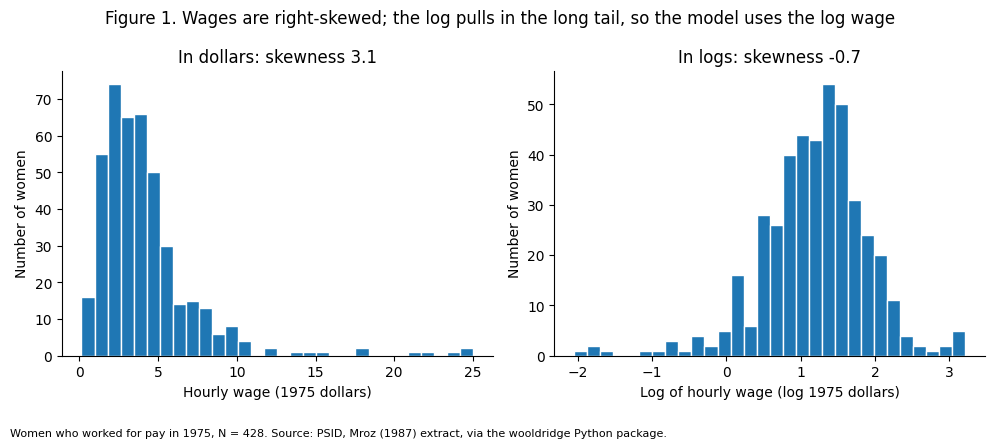

In [33]:
w = workers.copy()   # the regression sample: women with a wage

fig, ax = plt.subplots(1, 2, figsize=(10, 4.4))
ax[0].hist(w["wage"], bins=30, edgecolor="white")
ax[0].set(xlabel="Hourly wage (1975 dollars)", ylabel="Number of women",
          title=f"In dollars: skewness {w['wage'].skew():.1f}")
ax[1].hist(w["lwage"], bins=30, edgecolor="white")
ax[1].set(xlabel="Log of hourly wage (log 1975 dollars)", ylabel="Number of women",
          title=f"In logs: skewness {w['lwage'].skew():.1f}")
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
fig.suptitle("Figure 1. Wages are right-skewed; the log pulls in the long tail, so the model uses the log wage")
fig.tight_layout(rect=(0, 0.06, 1, 1))   # leave room at the bottom so the source note is inside the figure
fig.text(0.01, 0.01, f"Women who worked for pay in 1975, N = {len(w)}. " + SOURCE_NOTE, fontsize=8)
plt.show()


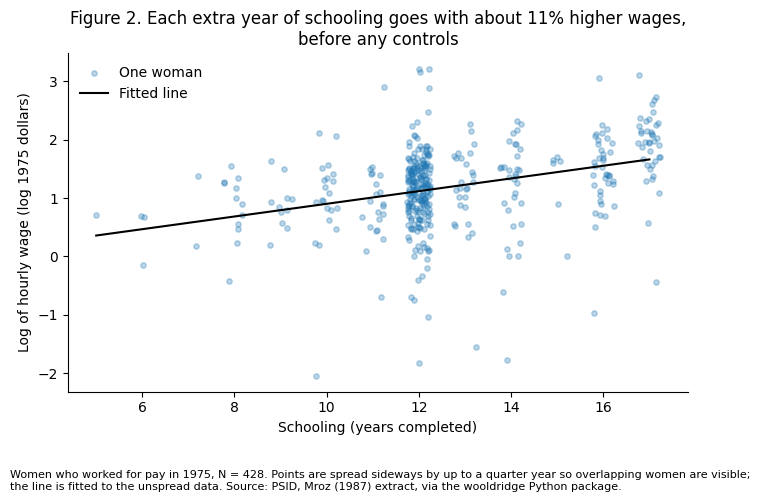

In [34]:
slope, intercept = np.polyfit(w["educ"], w["lwage"], 1)
PCT_BIV = 100 * (np.exp(slope) - 1)   # raw % difference per year of schooling, no controls

rng = np.random.default_rng(3916)                 # fixed seed so the figure is reproducible
jitter = rng.uniform(-0.25, 0.25, len(w))         # spread points sideways so overlapping women are visible

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(w["educ"] + jitter, w["lwage"], alpha=0.3, s=15, label="One woman")
x = np.arange(w["educ"].min(), w["educ"].max() + 1)
ax.plot(x, intercept + slope * x, color="black", label="Fitted line")
ax.set(xlabel="Schooling (years completed)", ylabel="Log of hourly wage (log 1975 dollars)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
ax.set_title(f"Figure 2. Each extra year of schooling goes with about {PCT_BIV:.0f}% higher wages,\nbefore any controls")
fig.tight_layout(rect=(0, 0.09, 1, 1))
fig.text(0.01, 0.01, f"Women who worked for pay in 1975, N = {len(w)}. Points are spread sideways by up to a quarter year so "
         "overlapping women are visible;\nthe line is fitted to the unspread data. " + SOURCE_NOTE, fontsize=8)
plt.show()


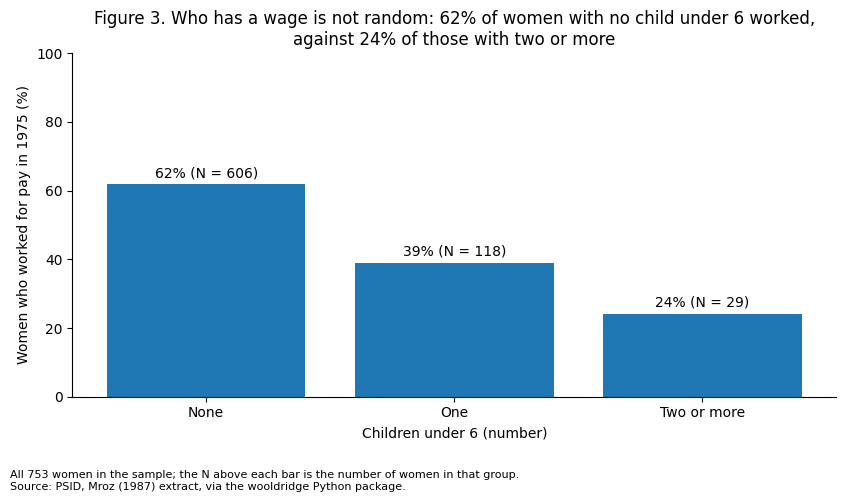

In [35]:
# Share of ALL women who worked, by number of children under 6
df["young_kids"] = df["kidslt6"].clip(upper=2).map({0: "None", 1: "One", 2: "Two or more"})
ORDER = ["None", "One", "Two or more"]
share = (df.groupby("young_kids")["inlf"].mean() * 100).reindex(ORDER)
counts = df["young_kids"].value_counts().reindex(ORDER)

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.bar(share.index, share)
for i, (group, value) in enumerate(share.items()):
    ax.text(i, value + 2, f"{value:.0f}% (N = {counts[group]})", ha="center")
ax.set(xlabel="Children under 6 (number)", ylabel="Women who worked for pay in 1975 (%)", ylim=(0, 100))
ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"Figure 3. Who has a wage is not random: {share['None']:.0f}% of women with no child under 6 worked,\n"
             f"against {share['Two or more']:.0f}% of those with two or more")
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.text(0.01, 0.01, f"All {len(df)} women in the sample; the N above each bar is the number of women in that group.\n"
         + SOURCE_NOTE, fontsize=8)
plt.show()


**Figure 1.** Most women earned a few dollars an hour while a small group earned far more, so the wage has a long right tail (skewness 3.09). The log pulls that tail in and lets coefficients be read as percent differences rather than a flat number of cents. The log overcorrects slightly: a handful of women report wages well under \$1 an hour, and these become a short left tail (skewness −0.69). That tail is much milder than the original one, so the model uses the log wage, and Section 4 checks whether those few very low wages drive the results.

**Figure 2.** Log wages rise with schooling before any controls: women with one more year of schooling earn about 11% more per hour on average. Most women have exactly 12 years of schooling, so that group anchors the line; the sideways spread shows how many women sit at each level. This raw relationship should not be read as the payoff to schooling alone: women with more schooling may also differ in work experience and family background, both of which can affect wages. That is why Section 3 moves to a multivariate regression and asks how much of this association remains once mother's schooling and experience are held constant.

**Figure 3.** Whether a woman has a wage at all is far from random: 62% of women with no child under 6 worked, against 24% of those with two or more. This figure demonstrates that employment participation varies across observed family characteristics. It supports the concern that the wage-observed sample is selective, although it cannot establish how unobserved wage offers affect participation, so it is consistent with, but not proof of, the MNAR framing in Section 1. Because wages exist only for women who worked, every estimate that follows describes working women.

## Section 3: The Model (25 pts)

Fit a multivariate OLS model and report it in a formatted regression table (coefficients, standard errors, N, R-squared), not a `summary()` dump. Interpret at least two coefficients in full: magnitude, units, direction, precision. For every control, say whether it blocks a confounding path or adds precision, and what would make it a bad control (Chapter 10). OLS only: no difference-in-differences estimate.

**The model.** For each woman *i* who worked in 1975, the main specification (column 3 of Table 3) is

$$\log(\text{wage}_i) = \beta_0 + \beta_1\,\text{educ}_i + \beta_2\,\text{motheduc}_i + \beta_3\,\text{exper}_i + \beta_4\,\frac{\text{exper}_i^2}{100} + u_i$$

estimated by OLS on the women with an observed wage. Table 3 adds controls one step at a time so the reader can see what each does to the schooling coefficient, $\beta_1$. Column (4) adds the number of children under 6 as a sensitivity check only. Standard errors are heteroskedasticity-robust (HC1), which Section 4 shows is needed. Because the outcome is in logs, a coefficient *b* means a one-unit change goes with a 100 × (e<sup>b</sup> − 1) percent difference in the hourly wage; for small *b* that is close to 100 × *b*.

**The role of every control, and what would make it a bad control**

| Variable | In the main model? | Role | What would make it a bad control |
|---|---|---|---|
| **Mother's schooling** | Yes | **Blocks a confounding path.** Mother's education may influence her daughter's educational opportunities, expectations, family resources, and access to networks. These factors may also affect later wages, for example through the jobs and contacts a woman can reach. Controlling for mother's education therefore helps account for some family-background differences, although it cannot eliminate all omitted-variable bias. Without it, part of the background–wage link would be credited to the woman's own schooling. It is moderately correlated with her schooling (0.39), so it can move the estimate, and adding it does: the schooling coefficient rises from 0.109 to 0.121 between columns (1) and (2). | A bad control is one the woman's schooling can change. Her mother's schooling was fixed before she was born, so it cannot be a mediator. Its weakness is that it is a partial proxy: it captures some of family background and none of her own ability, so it cannot remove all confounding (Section 5). |
| **Experience and experience squared** | Yes | **Separates the return to schooling from the return to time on the job,** and **adds precision**, because experience is one of the strongest predictors of wages. The square lets the wage curve flatten with career length, the standard Mincer shape. Holding it fixed answers the question as asked: women at the same point in their careers. | **It can be partly a mediator:** years in school are years not working, and more educated women stay in the labor force longer. So the brief's rule applies, and Table 3 shows both versions. Column (2) is the schooling–wage association without holding work experience constant; column (3) is the association among women with the same measured work experience. Column (2) is **not** the total causal effect: omitted-variable bias may remain in it, and it simply avoids conditioning on a variable that may partly lie on the pathway between schooling and wages. The text below the table compares the two. |
| **Children under 6** | **No** (column 4 only) | **Sensitivity check, not a control.** It is the most obvious difference between women with and without a wage (Figure 3), so a reader will ask whether it changes the answer; column (4) shows that. | **It is a bad control.** It is counted in 1975, years after every woman finished school, and more educated women tend to delay children, so schooling can change it. Holding it fixed would remove part of schooling's effect and could open a path through unmeasured family preferences. That is why it is excluded from the main model. |


In [36]:
# Four models, adding controls one step at a time. Robust (HC1) standard errors; Section 4 shows why.
# Column (3) is the main model. Column (4) adds children under 6, a post-treatment variable, only as a sensitivity check.
SPECS = {
    "(1)": "lwage ~ educ",
    "(2)": "lwage ~ educ + motheduc",
    "(3) Main": "lwage ~ educ + motheduc + exper + expersq",
    "(4) Sensitivity": "lwage ~ educ + motheduc + exper + expersq + kidslt6",
}
MODELS = {name: smf.ols(formula, data=w).fit(cov_type="HC1") for name, formula in SPECS.items()}
MAIN_NAME = "(3) Main"
MAIN = MODELS[MAIN_NAME]
SENS = MODELS["(4) Sensitivity"]

REG_LABELS = {"educ": "Schooling (years)", "motheduc": "Mother's schooling (years)",
              "exper": "Experience (years)", "expersq": "Experience squared / 100",
              "kidslt6": "Children under 6 (number)", "Intercept": "Constant"}

def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

def regression_table(models, labels):
    """Coefficients with stars, robust SEs in parentheses beneath, then N and R-squared."""
    rows, index = [], []
    for var, label in labels.items():
        rows.append([f"{m.params[var]:.4f}{stars(m.pvalues[var])}" if var in m.params else "" for m in models.values()])
        rows.append([f"({m.bse[var]:.4f})" if var in m.params else "" for m in models.values()])
        index += [label, ""]
    rows.append([f"{int(m.nobs)}" for m in models.values()]);      index.append("Observations (women)")
    rows.append([f"{m.rsquared:.3f}" for m in models.values()]);   index.append("R-squared")
    cols = pd.MultiIndex.from_product([["Dependent variable: log hourly wage"], list(models)])
    return pd.DataFrame(rows, index=index, columns=cols)

table3 = regression_table(MODELS, REG_LABELS)
print("Table 3. OLS estimates of the log hourly wage, married white women who worked for pay in 1975")
display(table3)
print("Notes: Robust (HC1) standard errors in parentheses. Experience squared is divided by 100, so its coefficient is "
      "readable; this changes no other estimate. Column (3) is the main model. Column (4) adds children under 6, "
      "which is measured after schooling ended and may be caused by it, so it is a sensitivity check only. "
      "*** p < 0.01, ** p < 0.05, * p < 0.10. " + SOURCE_NOTE)


Table 3. OLS estimates of the log hourly wage, married white women who worked for pay in 1975


Dependent variable: log hourly wage                                      
                                                           (1)        (2)   (3) Main (4) Sensitivity
Schooling (years)                                    0.1086***  0.1210***  0.1176***       0.1189***
                                                      (0.0134)   (0.0148)   (0.0146)        (0.0149)
Mother's schooling (years)                                      -0.0220**   -0.0183*        -0.0184*
                                                                 (0.0110)   (0.0109)        (0.0110)
Experience (years)                                                         0.0415***       0.0408***
                                                                            (0.0151)        (0.0150)
Experience squared / 100                                                   -0.0834**       -0.0827**
                                                                            (0.0414)        (0.0412)
Children under 6 (number)                                                                    -0.0560
                                                                                            (0.0981)
Constant                                               -0.1852    -0.1317  -0.4702**       -0.4699**
                                                      (0.1707)   (0.1732)   (0.2044)        (0.2043)
Observations (women)                                       428        428        428             428
R-squared                                                0.118      0.127      0.163           0.164

Notes: Robust (HC1) standard errors in parentheses. Experience squared is divided by 100, so its coefficient is readable; this changes no other estimate. Column (3) is the main model. Column (4) adds children under 6, which is measured after schooling ended and may be caused by it, so it is a sensitivity check only. *** p < 0.01, ** p < 0.05, * p < 0.10. Source: PSID, Mroz (1987) extract, via the wooldridge Python package.


In [37]:
b, ci, se, pv = MAIN.params, MAIN.conf_int(), MAIN.bse, MAIN.pvalues
pct = lambda x: 100 * (np.exp(x) - 1)    # turns a log-point coefficient into a % difference
updown = lambda x: "higher" if x > 0 else "lower"

def zero_check(lo, hi):
    return ("The interval excludes zero." if lo > 0 or hi < 0
            else "The interval includes zero, so the data cannot rule out no association.")

# Schooling
EDUC_PCT = pct(b["educ"])
EDUC_LO, EDUC_HI = pct(ci.loc["educ"])
MEAN_WAGE = w["wage"].mean()
EDUC_DOLLARS = MEAN_WAGE * EDUC_PCT / 100   # illustration only: the % difference applied at the average wage
# Four years of schooling: exact compounded % difference, 100(e^(4b) - 1), not 4 x the one-year %
EDUC_PCT4 = pct(4 * b["educ"])
EDUC_LO4, EDUC_HI4 = pct(4 * ci.loc["educ"])
EDUC_T = b["educ"] / se["educ"]

# Mother's schooling: per year, and over a four-year gap (roughly a high-school versus a college-educated mother)
MOTH_PCT = pct(b["motheduc"])
MOTH_LO, MOTH_HI = pct(ci.loc["motheduc"])
MOTH_PCT4 = pct(4 * b["motheduc"])
MOTH_LO4, MOTH_HI4 = pct(4 * ci.loc["motheduc"])

# Experience: the slope depends on where a woman is in her career
MEAN_EXPER = w["exper"].mean()
exper_slope = lambda e: b["exper"] + 2 * (b["expersq"] / 100) * e   # derivative of the quadratic
EXPER_PCT_5 = pct(exper_slope(5))
EXPER_PCT_MEAN = pct(exper_slope(MEAN_EXPER))
EXPER_PEAK = -b["exper"] / (2 * b["expersq"] / 100)

# Sensitivity: children under 6 (column 4)
KIDS_PCT = pct(SENS.params["kidslt6"])
KIDS_LO, KIDS_HI = pct(SENS.conf_int().loc["kidslt6"])

R_MOTHED_EDUC = w["motheduc"].corr(w["educ"])
EDUC_COLS = [m.params["educ"] for m in MODELS.values()]
EDUC_CHANGE_2_TO_3 = EDUC_COLS[2] - EDUC_COLS[1]   # what holding experience fixed does
EDUC_CHANGE_3_TO_4 = EDUC_COLS[3] - EDUC_COLS[2]   # what adding children under 6 does

# Sentences whose wording depends on the estimates, so the text stays true on any rerun
MOTH_READING = (
    "So the association is small next to the woman's own schooling, and its sign is the opposite of what a simple "
    "\"family advantage\" story predicts. The likely reading is that, once her own schooling is fixed, mother's "
    "schooling adds little independent information about wages; it may also reflect that women from better-off "
    "families could choose jobs for reasons other than pay."
    if b["motheduc"] < 0 else
    "So family background keeps a small positive association with wages beyond the woman's own schooling, "
    "consistent with routes such as expectations and job contacts.")
EXPER_SHAPE = ("Experience enters with a positive linear term and a negative squared term, so each extra year adds "
               "less than the one before." if b["expersq"] < 0 else
               "The squared term is not negative, so the experience profile does not flatten within the data.")
EXPER_PEAK_TEXT = (f"predicted wages peak at about {EXPER_PEAK:.0f} years, against a sample maximum of {w['exper'].max():.0f}."
                   if b["expersq"] < 0 else "there is no peak within the data.")
small = lambda d: "makes almost no difference" if abs(d) / se["educ"] < 0.5 else "matters"
OVB_DIRECTION = "down" if EDUC_COLS[1] > EDUC_COLS[0] else "up"

display(Markdown(f"""
**Schooling (the coefficient of interest).** Among working women with the same mother's schooling and the same years of experience, those with one more year of schooling earned on average **{EDUC_PCT:.1f}% more per hour** (coefficient {b['educ']:.4f} log points, robust standard error {se['educ']:.4f}). The 95% confidence interval runs from {EDUC_LO:.1f}% to {EDUC_HI:.1f}%. {zero_check(EDUC_LO, EDUC_HI)} The estimate is {EDUC_T:.1f} standard errors from zero, so it is precise. The percentage is the main result. As an *approximate illustration* only, applying {EDUC_PCT:.1f}% at the sample's average wage of \\${MEAN_WAGE:.2f} gives about \\${EDUC_DOLLARS:.2f} more per hour in 1975 dollars; because the model is in logs, the implied dollar gap is larger for women with higher wages and smaller for women with lower wages, so this is not the dollar increase for every woman. Over four years of schooling, roughly a college degree compared with a high-school diploma, the exact compounded difference is 100 × (e<sup>4b</sup> − 1) = **{EDUC_PCT4:.1f}%** (95% CI {EDUC_LO4:.1f}% to {EDUC_HI4:.1f}%), rather than four times the one-year figure. This is a conditional association, not a causal effect (Section 5).

**Mother's schooling.** Holding the woman's own schooling and experience constant, each extra year of her mother's schooling is associated with a **{abs(MOTH_PCT):.1f}% {updown(MOTH_PCT)} hourly wage** (coefficient {b['motheduc']:.4f}, robust standard error {se['motheduc']:.4f}, p = {pv['motheduc']:.3f}). The 95% confidence interval runs from {MOTH_LO:.1f}% to {MOTH_HI:.1f}%. {zero_check(MOTH_LO, MOTH_HI)} Over a four-year gap in mother's schooling, about the difference between a mother who finished high school and one who finished college, the association is {abs(MOTH_PCT4):.1f}% {updown(MOTH_PCT4)} (95% CI {MOTH_LO4:.1f}% to {MOTH_HI4:.1f}%). {MOTH_READING} Its job in the model is to remove a confounding path, not to be interpreted causally.

**Experience.** {EXPER_SHAPE} Early in a career (5 years in) one more year of experience goes with about {EXPER_PCT_5:.1f}% higher wages; at the sample average of {MEAN_EXPER:.1f} years, about {EXPER_PCT_MEAN:.1f}%; {EXPER_PEAK_TEXT}

**Sensitivity check: children under 6 (column 4).** Adding the number of children under 6 moves the schooling coefficient from {EDUC_COLS[2]:.4f} to {EDUC_COLS[3]:.4f}, a change of {EDUC_CHANGE_3_TO_4:+.4f} ({abs(EDUC_CHANGE_3_TO_4) / se['educ']:.2f} of one robust standard error). Each child under 6 is associated with a {abs(KIDS_PCT):.1f}% {updown(KIDS_PCT)} wage, with a 95% interval from {KIDS_LO:.1f}% to {KIDS_HI:.1f}%: {zero_check(KIDS_LO, KIDS_HI).lower()} Holding young children fixed {small(EDUC_CHANGE_3_TO_4)} to the answer.

**What each control did to the schooling coefficient.** Column (1), with no controls, gives {EDUC_COLS[0]:.4f}. Adding mother's schooling (column 2) changes it to {EDUC_COLS[1]:.4f}: mother's schooling is correlated {R_MOTHED_EDUC:.2f} with the woman's own schooling, and its partial association with the wage has the sign shown in column (2), so leaving it out biases the schooling coefficient {OVB_DIRECTION}. Holding experience fixed (column 3, the main model) changes it by {EDUC_CHANGE_2_TO_3:+.4f} to {EDUC_COLS[2]:.4f}, {abs(EDUC_CHANGE_2_TO_3) / se['educ']:.2f} of a standard error. The two columns answer different questions. Column (2) is the schooling–wage association without holding work experience constant; column (3) is the schooling–wage association among women with the same measured work experience. Neither is a causal effect: the model without experience does not identify the total causal effect of schooling, because omitted-variable bias may remain; it simply avoids conditioning on a variable that may partly lie on the pathway between schooling and wages. Here, choosing between the two {small(EDUC_CHANGE_2_TO_3)}. The main model's R-squared is {MAIN.rsquared:.3f}, N = {int(MAIN.nobs)}.
"""))



**Schooling (the coefficient of interest).** Among working women with the same mother's schooling and the same years of experience, those with one more year of schooling earned on average **12.5% more per hour** (coefficient 0.1176 log points, robust standard error 0.0146). The 95% confidence interval runs from 9.3% to 15.7%. The interval excludes zero. The estimate is 8.1 standard errors from zero, so it is precise. The percentage is the main result. As an *approximate illustration* only, applying 12.5% at the sample's average wage of \$4.18 gives about \$0.52 more per hour in 1975 dollars; because the model is in logs, the implied dollar gap is larger for women with higher wages and smaller for women with lower wages, so this is not the dollar increase for every woman. Over four years of schooling, roughly a college degree compared with a high-school diploma, the exact compounded difference is 100 × (e<sup>4b</sup> − 1) = **60.1%** (95% CI 42.8% to 79.4%), rather than four times the one-year figure. This is a conditional association, not a causal effect (Section 5).

**Mother's schooling.** Holding the woman's own schooling and experience constant, each extra year of her mother's schooling is associated with a **1.8% lower hourly wage** (coefficient -0.0183, robust standard error 0.0109, p = 0.093). The 95% confidence interval runs from -3.9% to 0.3%. The interval includes zero, so the data cannot rule out no association. Over a four-year gap in mother's schooling, about the difference between a mother who finished high school and one who finished college, the association is 7.1% lower (95% CI -14.7% to 1.2%). So the association is small next to the woman's own schooling, and its sign is the opposite of what a simple "family advantage" story predicts. The likely reading is that, once her own schooling is fixed, mother's schooling adds little independent information about wages; it may also reflect that women from better-off families could choose jobs for reasons other than pay. Its job in the model is to remove a confounding path, not to be interpreted causally.

**Experience.** Experience enters with a positive linear term and a negative squared term, so each extra year adds less than the one before. Early in a career (5 years in) one more year of experience goes with about 3.4% higher wages; at the sample average of 13.0 years, about 2.0%; predicted wages peak at about 25 years, against a sample maximum of 38.

**Sensitivity check: children under 6 (column 4).** Adding the number of children under 6 moves the schooling coefficient from 0.1176 to 0.1189, a change of +0.0013 (0.09 of one robust standard error). Each child under 6 is associated with a 5.4% lower wage, with a 95% interval from -22.0% to 14.6%: the interval includes zero, so the data cannot rule out no association. Holding young children fixed makes almost no difference to the answer.

**What each control did to the schooling coefficient.** Column (1), with no controls, gives 0.1086. Adding mother's schooling (column 2) changes it to 0.1210: mother's schooling is correlated 0.39 with the woman's own schooling, and its partial association with the wage has the sign shown in column (2), so leaving it out biases the schooling coefficient down. Holding experience fixed (column 3, the main model) changes it by -0.0034 to 0.1176, 0.23 of a standard error. The two columns answer different questions. Column (2) is the schooling–wage association without holding work experience constant; column (3) is the schooling–wage association among women with the same measured work experience. Neither is a causal effect: the model without experience does not identify the total causal effect of schooling, because omitted-variable bias may remain; it simply avoids conditioning on a variable that may partly lie on the pathway between schooling and wages. Here, choosing between the two makes almost no difference. The main model's R-squared is 0.163, N = 428.


## Section 4: Diagnostics (20 pts)

Residuals against fitted values and against your main predictor; a constant-variance check, with robust standard errors if it fails; variance inflation factors, interpreted; at least one influential-observation check.

**Start only after Topic 14.** Write Sections 1 to 3 first; they do not depend on it.

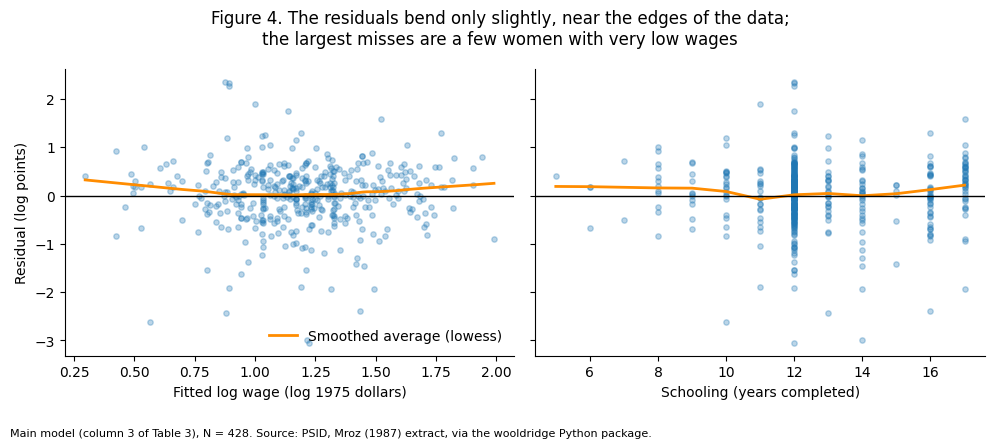

Table 4. Conventional and robust standard errors, main model (column 3)


,Conventional SE,Robust (HC1) SE,"Ratio, robust / conventional"
Constant,0.2004,0.2044,1.0196
Schooling (years),0.0153,0.0146,0.9513
Mother's schooling (years),0.0106,0.0109,1.0264
Experience (years),0.0131,0.0151,1.1523
Experience squared / 100,0.0393,0.0414,1.0554


Notes: Coefficients are identical in both columns; only the standard errors differ. Source: PSID, Mroz (1987) extract, via the wooldridge Python package.



**1. Residuals (Figure 4).** If the functional form were wrong, the residuals would bend away from zero in one of the panels; the orange smoothed line makes any bend visible. It bends away from zero only near the edges of the data, where few women sit: its largest distance from zero is 0.32 log points against fitted wages and 0.21 against schooling, small next to residuals that spread over several log points. So a straight line in schooling with a quadratic in experience captures the average shape of the data. The one clear feature is a handful of large negative residuals, down to -3.0 log points. These are the women with very low reported wages that formed the left tail in Figure 1. They make the residual distribution skewed to the left and heavy-tailed (skewness -0.74, kurtosis 6.7, against 0 and 3 for a normal distribution). OLS coefficients do not need normal errors to be unbiased, and with 428 women the confidence intervals rest on large-sample approximations that are reasonable here; check 4 shows that these women do not drive the estimate.

**2. Constant variance (Breusch–Pagan, Table 4).** The test asks whether the size of the errors depends on the regressors. It rejects constant variance (statistic 12.87 on 4 degrees of freedom, p = 0.012), so conventional standard errors would be wrong and robust (HC1) standard errors are needed. Table 3 already uses them. Table 4 shows what the correction does: robust errors are larger than conventional ones for mother's schooling, experience and experience squared; they are smaller for schooling. For schooling the robust error is 0.0146 against 0.0153 conventional, so the schooling result is 7.7 or 8.1 standard errors from zero: equally strong either way.


In [38]:
# Same main model with conventional SEs, used for residuals, the variance test and influence (coefficients are identical)
MAIN_OLS = smf.ols(SPECS[MAIN_NAME], data=w).fit()
lowess = sm.nonparametric.lowess   # smoothed line through the residuals: a curve would show a missed shape
# How far the smoothed line strays from zero, in log points (a check on the "no curve" reading)
LOWESS_MAX_FIT = np.abs(lowess(MAIN_OLS.resid, MAIN_OLS.fittedvalues, frac=0.5)[:, 1]).max()
LOWESS_MAX_EDUC = np.abs(lowess(MAIN_OLS.resid, w["educ"], frac=0.5)[:, 1]).max()
FLAT = max(LOWESS_MAX_FIT, LOWESS_MAX_EDUC) < 0.2   # under 0.2 log points: no curve worth modelling

fig, ax = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
for a, xvar, xlab in [(ax[0], MAIN_OLS.fittedvalues, "Fitted log wage (log 1975 dollars)"),
                      (ax[1], w["educ"], "Schooling (years completed)")]:
    a.scatter(xvar, MAIN_OLS.resid, alpha=0.3, s=15)
    smooth = lowess(MAIN_OLS.resid, xvar, frac=0.5)
    a.plot(smooth[:, 0], smooth[:, 1], color="darkorange", lw=2, label="Smoothed average (lowess)")
    a.axhline(0, color="black", lw=1)
    a.set(xlabel=xlab)
    a.spines[["top", "right"]].set_visible(False)
ax[0].set_ylabel("Residual (log points)")
ax[0].legend(frameon=False, loc="lower right")
fig.suptitle(("Figure 4. The residuals show no curve against fitted wages or schooling;\n" if FLAT
              else "Figure 4. The residuals bend only slightly, near the edges of the data;\n")
             + "the largest misses are a few women with very low wages")
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.text(0.01, 0.01, f"Main model (column 3 of Table 3), N = {len(w)}. " + SOURCE_NOTE, fontsize=8)
plt.show()

# Shape of the residual distribution (a normal distribution has skewness 0 and kurtosis 3)
RESID_SKEW = stats.skew(MAIN_OLS.resid)
RESID_KURT = stats.kurtosis(MAIN_OLS.resid, fisher=False)
RESID_MIN = MAIN_OLS.resid.min()

# Breusch-Pagan test for constant variance
BP_STAT, BP_P, _, _ = het_breuschpagan(MAIN_OLS.resid, MAIN_OLS.model.exog)
BP_DF = MAIN_OLS.model.exog.shape[1] - 1

se_compare = pd.DataFrame({"Conventional SE": MAIN_OLS.bse, "Robust (HC1) SE": MAIN.bse})
se_compare["Ratio, robust / conventional"] = se_compare["Robust (HC1) SE"] / se_compare["Conventional SE"]
print("Table 4. Conventional and robust standard errors, main model (column 3)")
display(se_compare.rename(index=REG_LABELS).round(4))
print("Notes: Coefficients are identical in both columns; only the standard errors differ. " + SOURCE_NOTE)

SHORT = {"educ": "schooling", "motheduc": "mother's schooling", "exper": "experience", "expersq": "experience squared"}
and_join = lambda xs: xs[0] if len(xs) == 1 else ", ".join(xs[:-1]) + " and " + xs[-1]
bigger = [SHORT[v] for v in SHORT if se_compare.loc[v, "Ratio, robust / conventional"] > 1]
smaller = [SHORT[v] for v in SHORT if se_compare.loc[v, "Ratio, robust / conventional"] <= 1]
SE_COMPARE_TEXT = ("larger than conventional ones for " + (and_join(bigger) if bigger else "no regressor")
                   + ("; they are smaller for " + and_join(smaller) if smaller else ""))
EDUC_T_ROBUST = MAIN.params["educ"] / MAIN.bse["educ"]
EDUC_SE_CONV = MAIN_OLS.bse["educ"]
EDUC_T_CONV = MAIN_OLS.params["educ"] / EDUC_SE_CONV

form_text = ("It stays close to zero throughout" if FLAT else
             "It bends away from zero only near the edges of the data, where few women sit")

if BP_P < 0.05:
    bp_text = (f"It rejects constant variance (statistic {BP_STAT:.2f} on {BP_DF} degrees of freedom, p = {BP_P:.3f}), "
               "so conventional standard errors would be wrong and robust (HC1) standard errors are needed. "
               "Table 3 already uses them.")
else:
    bp_text = (f"It does not reject constant variance at the 5% level (statistic {BP_STAT:.2f} on {BP_DF} degrees of "
               f"freedom, p = {BP_P:.3f}). Failing to reject is not proof of constant variance, and robust (HC1) "
               "standard errors are valid whether or not the variance is constant, so Table 3 keeps them as the safe choice.")

display(Markdown(f"""
**1. Residuals (Figure 4).** If the functional form were wrong, the residuals would bend away from zero in one of the panels; the orange smoothed line makes any bend visible. {form_text}: its largest distance from zero is {LOWESS_MAX_FIT:.2f} log points against fitted wages and {LOWESS_MAX_EDUC:.2f} against schooling, small next to residuals that spread over several log points. So a straight line in schooling with a quadratic in experience captures the average shape of the data. The one clear feature is a handful of large negative residuals, down to {RESID_MIN:.1f} log points. These are the women with very low reported wages that formed the left tail in Figure 1. They make the residual distribution skewed to the left and heavy-tailed (skewness {RESID_SKEW:.2f}, kurtosis {RESID_KURT:.1f}, against 0 and 3 for a normal distribution). OLS coefficients do not need normal errors to be unbiased, and with {int(MAIN.nobs)} women the confidence intervals rest on large-sample approximations that are reasonable here; check 4 shows that these women do not drive the estimate.

**2. Constant variance (Breusch–Pagan, Table 4).** The test asks whether the size of the errors depends on the regressors. {bp_text} Table 4 shows what the correction does: robust errors are {SE_COMPARE_TEXT}. For schooling the robust error is {MAIN.bse['educ']:.4f} against {EDUC_SE_CONV:.4f} conventional, so the schooling result is {EDUC_T_CONV:.1f} or {EDUC_T_ROBUST:.1f} standard errors from zero: equally strong either way.
"""))


In [39]:
# Variance inflation factors for the main model's regressors
X = sm.add_constant(w[["educ", "motheduc", "exper", "expersq"]])
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=X.columns[1:])
print("Table 5. Variance inflation factors, main model (column 3)")
display(vif.rename(index=REG_LABELS).round(2).to_frame("VIF"))
print("Notes: VIF = 1 / (1 - R-squared from regressing one regressor on the others). " + SOURCE_NOTE)
VIF_EDUC, VIF_MOTH = vif["educ"], vif["motheduc"]
VIF_EXPER, VIF_EXPERSQ = vif["exper"], vif["expersq"]

display(Markdown(f"""
**3. Multicollinearity (Table 5).** A VIF says how much a coefficient's variance is inflated by overlap with the other regressors; concern usually starts around 5 to 10. Schooling's VIF is {VIF_EDUC:.2f}, so its standard error is only {np.sqrt(VIF_EDUC):.2f} times what it would be if schooling were unrelated to the other regressors, and mother's schooling's is {VIF_MOTH:.2f}. Neither is close to the range for concern, so the schooling estimate is not blurred by overlap with family background or experience. Experience and experience squared have VIFs of {VIF_EXPER:.1f} and {VIF_EXPERSQ:.1f}. They are naturally correlated because one is mathematically constructed from the other (the square of experience, divided by 100), so a high VIF for these two terms is expected and does not mean the schooling coefficient is unreliable: what governs the precision of the schooling estimate is schooling's own VIF of {VIF_EDUC:.2f}. The high values are also harmless for the experience terms themselves: the two are read together (the experience slope and peak in Section 3) and neither is the coefficient of interest. Any condition-number warning in the Appendix output reflects the scale of the regressors, not harmful overlap; dividing experience squared by 100 changes none of the VIFs.
"""))


Table 5. Variance inflation factors, main model (column 3)


,VIF
Schooling (years),1.18
Mother's schooling (years),1.19
Experience (years),10.83
Experience squared / 100,10.86


Notes: VIF = 1 / (1 - R-squared from regressing one regressor on the others). Source: PSID, Mroz (1987) extract, via the wooldridge Python package.



**3. Multicollinearity (Table 5).** A VIF says how much a coefficient's variance is inflated by overlap with the other regressors; concern usually starts around 5 to 10. Schooling's VIF is 1.18, so its standard error is only 1.09 times what it would be if schooling were unrelated to the other regressors, and mother's schooling's is 1.19. Neither is close to the range for concern, so the schooling estimate is not blurred by overlap with family background or experience. Experience and experience squared have VIFs of 10.8 and 10.9. They are naturally correlated because one is mathematically constructed from the other (the square of experience, divided by 100), so a high VIF for these two terms is expected and does not mean the schooling coefficient is unreliable: what governs the precision of the schooling estimate is schooling's own VIF of 1.18. The high values are also harmless for the experience terms themselves: the two are read together (the experience slope and peak in Section 3) and neither is the coefficient of interest. Any condition-number warning in the Appendix output reflects the scale of the regressors, not harmful overlap; dividing experience squared by 100 changes none of the VIFs.


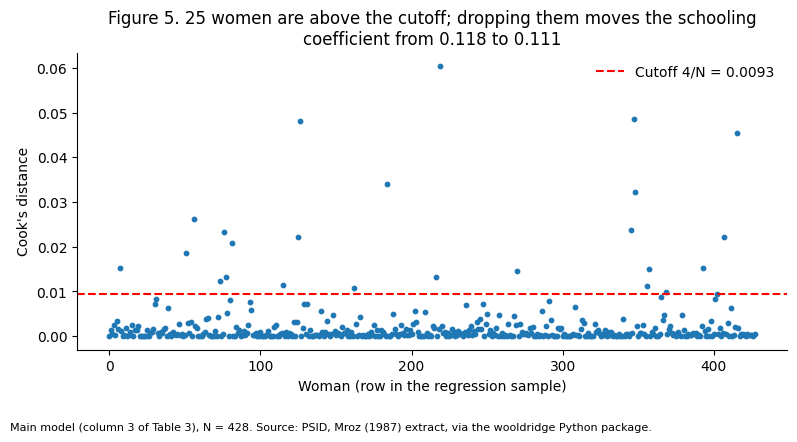

Table 6. The five most influential women


,Cook's distance,Hourly wage (1975 $),Schooling (years completed),Labor-market experience (years),Mother's schooling (years)
219,0.060,0.128,10,1,10
347,0.048,0.171,14,10,16
126,0.048,0.383,16,4,7
415,0.045,0.214,13,1,12
184,0.034,25.000,12,2,7


Notes: Main model (column 3 of Table 3). Source: PSID, Mroz (1987) extract, via the wooldridge Python package.



**4. Influential observations (Figure 5, Table 6).** Cook's distance measures how much the fitted model moves when one woman is dropped. It is a flag for investigation, not an automatic reason to delete an observation. Using the common 4/N cutoff (0.0093), 25 women are flagged. Four of the five most influential report wages under 40 cents an hour (the lowest is \$0.13), which most likely reflects overstated hours rather than real pay. The schooling coefficient is 0.1176 (robust SE 0.0146) with all 428 women and 0.1114 (robust SE 0.0117) with the 25 flagged women removed (N = 403), a shift of 0.43 robust standard errors and still inside the main model's 95% confidence interval, so the result does not depend on them. Having investigated them, the main model keeps them: they are genuine survey responses, and deleting observations because they fit badly would be choosing the data to suit the model. The before-and-after comparison shows the conclusion does not hinge on that choice.


In [40]:
# Influence: Cook's distance, with the common 4/N cutoff
cooks = MAIN_OLS.get_influence().cooks_distance[0]
COOK_CUT = 4 / len(w)
influential = w.index[cooks > COOK_CUT]
N_INFLUENTIAL = len(influential)

# Refit without the influential women and compare the schooling coefficient
MAIN_DROP = smf.ols(SPECS[MAIN_NAME], data=w.drop(influential)).fit(cov_type="HC1")
EDUC_DROP = MAIN_DROP.params["educ"]
EDUC_DROP_SHIFT_SE = (EDUC_DROP - MAIN.params["educ"]) / MAIN.bse["educ"]

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.scatter(range(len(cooks)), cooks, s=10)
ax.axhline(COOK_CUT, color="red", linestyle="--", label=f"Cutoff 4/N = {COOK_CUT:.4f}")
ax.set(xlabel="Woman (row in the regression sample)", ylabel="Cook's distance")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
ax.set_title(f"Figure 5. {N_INFLUENTIAL} women are above the cutoff; dropping them moves the schooling\n"
             f"coefficient from {MAIN.params['educ']:.3f} to {EDUC_DROP:.3f}")
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.text(0.01, 0.01, f"Main model (column 3 of Table 3), N = {len(w)}. " + SOURCE_NOTE, fontsize=8)
plt.show()

top5 = w.loc[w.index[np.argsort(cooks)[::-1][:5]], ["wage", "educ", "exper", "motheduc"]]
top5.insert(0, "Cook's distance", np.sort(cooks)[::-1][:5])
print("Table 6. The five most influential women")
display(top5.rename(columns=LABELS).round(3))
print("Notes: Main model (column 3 of Table 3). " + SOURCE_NOTE)
N_TOP5_UNDER_40C = int((top5["wage"] < 0.40).sum())
TOP5_MIN_WAGE = top5["wage"].min()
inside = MAIN.conf_int().loc["educ", 0] <= EDUC_DROP <= MAIN.conf_int().loc["educ", 1]
COUNT_WORD = ["None", "One", "Two", "Three", "Four", "All five"][N_TOP5_UNDER_40C]
LOW_WAGE_TEXT = (f"{COUNT_WORD} of the five most influential {'reports a wage' if N_TOP5_UNDER_40C == 1 else 'report wages'} under 40 cents an hour "
                 f"(the lowest is ${TOP5_MIN_WAGE:.2f}), which most likely reflects overstated hours rather than real pay."
                 if N_TOP5_UNDER_40C > 0 else
                 f"The five most influential women are listed in Table 6; the lowest wage among them is ${TOP5_MIN_WAGE:.2f}.")
LOW_WAGE_MD = LOW_WAGE_TEXT.replace("$", "\\$")   # escape $ so Markdown does not read it as maths
INSIDE_TEXT = " and still inside the main model's 95% confidence interval" if inside else ""
HINGE_TEXT = ("The before-and-after comparison shows the conclusion does not hinge on that choice."
              if abs(EDUC_DROP_SHIFT_SE) < 0.5 else
              "Because the estimate does shift, both versions are reported here.")
INFL_VERDICT = ("so the result does not depend on them" if abs(EDUC_DROP_SHIFT_SE) < 0.5
                else "a noticeable shift, so the result should be read with them in mind")

display(Markdown(f"""
**4. Influential observations (Figure 5, Table 6).** Cook's distance measures how much the fitted model moves when one woman is dropped. It is a flag for investigation, not an automatic reason to delete an observation. Using the common 4/N cutoff ({COOK_CUT:.4f}), {N_INFLUENTIAL} women are flagged. {LOW_WAGE_MD} The schooling coefficient is {MAIN.params['educ']:.4f} (robust SE {MAIN.bse['educ']:.4f}) with all {int(MAIN.nobs)} women and {EDUC_DROP:.4f} (robust SE {MAIN_DROP.bse['educ']:.4f}) with the {N_INFLUENTIAL} flagged women removed (N = {int(MAIN_DROP.nobs)}), a shift of {abs(EDUC_DROP_SHIFT_SE):.2f} robust standard errors{INSIDE_TEXT}, {INFL_VERDICT}. Having investigated them, the main model keeps them: they are genuine survey responses, and deleting observations because they fit badly would be choosing the data to suit the model. {HINGE_TEXT}
"""))


**What the diagnostics mean together.** The diagnostics provide evidence that the main specification is reasonably stable with respect to functional form, heteroskedasticity, multicollinearity, and influential observations: the residuals show no systematic curve, robust standard errors guard against uneven variance, overlap among the regressors does not inflate the schooling estimate's uncertainty, and dropping the flagged women changes the schooling coefficient little. However, they do not rule out omitted-variable bias or selection into employment, because both problems can leave no trace in the residuals of the women we observe. Section 5 takes those up.


## Section 5: Threats and Conclusion (10 pts)

First the threats: what would have to be true for your main coefficient to be causal, is it, and if not, what your estimate is instead. Then the conclusion: what you found, how confident a reader should be, and what you would do with another month. Half a page. No new results, so there is no code cell here.

**Threats to a causal reading.** For the schooling coefficient to be the causal effect of schooling on wages, two women with the same mother's schooling and experience would have to differ in schooling only for reasons unrelated to their earning power. That is not believable here, for three reasons.

1. **Omitted ability and motivation.** Women who stayed in school longer were probably more able or more motivated, and those traits raise wages on their own. Mother's schooling captures only part of family background and none of a woman's own ability. This pushes the estimate *up*.
2. **Selection into work.** As Section 1 argued, wages are observed only for women who chose to work, and that choice may depend on the unobserved wage offer. One plausible mechanism produces downward bias: less-educated women who work may have unusually favorable wage offers, which would flatten the schooling–wage slope. However, the direction and magnitude of selection bias cannot be established from the observed wages alone.
3. **Measurement.** Years of schooling ignore school quality, and random error in reported schooling pushes the estimate toward zero. Error in reported hours adds noise to the wage; that mainly costs precision rather than causing bias.

Ability bias likely pushes the estimate up, while the direction of selection bias is uncertain, so the net bias cannot be signed. Experience may also carry part of schooling's effect, so the estimate is a return *holding experience fixed*, not the total effect of schooling.

**What the estimate is instead.** The schooling coefficient is a **conditional association**: the average difference in log hourly wages between married white women who worked in 1975, differ by one year of schooling, and have the same mother's schooling and experience. It is a descriptive comparison for this population, not the causal return to schooling, and not a statement about married women who did not work.

**Conclusion.** Among married white women who worked in 1975, one more year of schooling goes with about 12.5% higher hourly wages, holding mother's schooling and experience constant (Table 3, column 3; the 95% confidence interval in Section 3 lies well above zero). The estimate barely moves when experience is held fixed, when young children are added, or when influential women are dropped, so as a description of this sample it is solid. As a causal effect it deserves much less confidence, because ability bias and selection into work are both plausible and neither can be measured with these data.

With another month I would do three things. First, explore a Heckman selection model. It would require a credible exclusion restriction: a variable that affects employment participation without directly affecting the woman's wage offer. Husband's wage and other family income may help predict participation, but their exclusion from the wage equation would need to be justified rather than assumed, since they could be related to household background, location and local job opportunities that also shape her wage offer. I would look for a better-justified candidate (for example, variation in local childcare costs or availability, which changes the cost of working rather than the wage offered) and show how sensitive the estimate is to the choice. Second, find variation in schooling unrelated to ability, such as distance to the nearest college, which needs richer data than this file; mother's schooling would be a doubtful instrument, since it keeps its own (weak) association with wages in Table 3. Third, repeat the analysis on later PSID years and a broader sample, including single women and women of color, to see whether the return to schooling has changed and for whom.


## Appendix

The regression table, the diagnostics output and any extra figures. The appendix does not count toward the 6–8 page limit of the report.

In [41]:
# Full statsmodels output for the main model, for reference
print(MAIN.summary())
print("\nSensitivity check, column (4) of Table 3:")
print(SENS.summary())

                            OLS Regression Results                            
Dep. Variable:                  lwage   R-squared:                       0.163
Model:                            OLS   Adj. R-squared:                  0.155
Method:                 Least Squares   F-statistic:                     21.31
Date:                Mon, 09 Nov 2026   Prob (F-statistic):           4.97e-16
Time:                        21:48:20   Log-Likelihood:                -430.10
No. Observations:                 428   AIC:                             870.2
Df Residuals:                     423   BIC:                             890.5
Df Model:                           4                                         
Covariance Type:                  HC1                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.4702      0.204     -2.301      0.0

## Numbers my report quotes

Every number in your report, each with a name that says where it comes from. A number in the report that this cell does not print is unsupported, and is graded as if it were missing. Keep it the last code cell.

In [42]:
REPORT_NUMBERS = {
    # Section 1
    "Section 1: women in the sample": len(df),
    "Section 1: columns in the file as loaded": FILE_COLS,
    "Section 1: women who worked (wage observed)": len(workers),
    "Section 1: women who did not work (wage missing)": len(nonworkers),
    "Section 1: share with wage missing": round(df["wage"].isna().mean(), 3),
    "Section 1: mean hourly wage among workers (1975 $)": round(w["wage"].mean(), 2),
    "Section 1: schooling gap, workers minus non-workers (years)": round(table2.loc[LABELS["educ"], "Difference"], 2),
    "Section 1: children-under-6 gap, workers minus non-workers": round(table2.loc[LABELS["kidslt6"], "Difference"], 3),
    "Section 1: other-family-income gap, workers minus non-workers ($1,000s)": round(table2.loc[LABELS["nwifeinc"], "Difference"], 2),
    "Section 1: experience gap, workers minus non-workers (years)": round(table2.loc[LABELS["exper"], "Difference"], 2),
    "Section 1: Table 2 p-values (all four gaps above)": [round(table2.loc[LABELS[v], "p-value"], 3) for v in ["educ", "kidslt6", "nwifeinc", "exper"]],
    "Section 1: minimum of family income minus her earnings, regression sample ($1,000s)": round(NWIFEINC_MIN, 2),
    # Section 2
    "Section 2: skewness of wage": round(w["wage"].skew(), 2),
    "Section 2: skewness of log wage": round(w["lwage"].skew(), 2),
    "Section 2: raw % wage difference per year of schooling": round(PCT_BIV, 1),
    "Section 2: % working, no child under 6": round(share["None"], 1),
    "Section 2: % working, two or more children under 6": round(share["Two or more"], 1),
    # Section 3
    "Section 3: N in the regression": int(MAIN.nobs),
    "Section 3: schooling coefficient, columns (1)-(4)": [round(float(x), 4) for x in EDUC_COLS],
    "Section 3: change in schooling coefficient when mother's schooling is added": round(EDUC_COLS[1] - EDUC_COLS[0], 4),
    "Section 3: change in schooling coefficient, column (2) to column (3)": round(EDUC_CHANGE_2_TO_3, 4),
    "Section 3: change in schooling coefficient, column (3) to column (4)": round(EDUC_CHANGE_3_TO_4, 4),
    "Section 3: correlation, mother's schooling and own schooling": round(R_MOTHED_EDUC, 2),
    "Section 3: schooling coefficient, main model": round(b["educ"], 4),
    "Section 3: schooling robust SE, main model": round(se["educ"], 4),
    "Section 3: schooling t-statistic (robust), main model": round(EDUC_T, 1),
    "Section 3: % wage difference per year of schooling": round(EDUC_PCT, 1),
    "Section 3: 95% CI for schooling (%)": (round(float(EDUC_LO), 1), round(float(EDUC_HI), 1)),
    "Section 3: $ per hour per year of schooling (illustration at mean wage)": round(EDUC_DOLLARS, 2),
    "Section 3: exact % difference, four years of schooling": round(EDUC_PCT4, 1),
    "Section 3: 95% CI, four years of schooling (%)": (round(float(EDUC_LO4), 1), round(float(EDUC_HI4), 1)),
    "Section 3: mother's schooling coefficient, main model": round(b["motheduc"], 4),
    "Section 3: mother's schooling robust SE, main model": round(se["motheduc"], 4),
    "Section 3: mother's schooling p-value, main model": round(pv["motheduc"], 3),
    "Section 3: % wage difference per year of mother's schooling": round(MOTH_PCT, 1),
    "Section 3: 95% CI for mother's schooling (%)": (round(float(MOTH_LO), 1), round(float(MOTH_HI), 1)),
    "Section 3: % wage difference, four years of mother's schooling": round(MOTH_PCT4, 1),
    "Section 3: 95% CI, four years of mother's schooling (%)": (round(float(MOTH_LO4), 1), round(float(MOTH_HI4), 1)),
    "Section 3: % return to a year of experience at 5 years": round(EXPER_PCT_5, 1),
    "Section 3: mean experience among workers (years)": round(MEAN_EXPER, 1),
    "Section 3: % return to a year of experience at the mean": round(EXPER_PCT_MEAN, 1),
    "Section 3: experience where wages peak (years)": round(EXPER_PEAK, 1),
    "Section 3: maximum experience in the sample (years)": int(w["exper"].max()),
    "Section 3: % wage difference per child under 6 (column 4)": round(KIDS_PCT, 1),
    "Section 3: 95% CI for children under 6, column 4 (%)": (round(float(KIDS_LO), 1), round(float(KIDS_HI), 1)),
    "Section 3: R-squared, main model": round(MAIN.rsquared, 3),
    # Section 4
    "Section 4: largest lowess distance from zero, fitted / schooling (log points)": (round(LOWESS_MAX_FIT, 2), round(LOWESS_MAX_EDUC, 2)),
    "Section 4: most negative residual (log points)": round(RESID_MIN, 1),
    "Section 4: residual skewness (main model)": round(RESID_SKEW, 2),
    "Section 4: residual kurtosis (main model)": round(RESID_KURT, 1),
    "Section 4: Breusch-Pagan statistic": round(BP_STAT, 2),
    "Section 4: Breusch-Pagan degrees of freedom": BP_DF,
    "Section 4: Breusch-Pagan p-value": round(BP_P, 3),
    "Section 4: conventional SE for schooling": round(EDUC_SE_CONV, 4),
    "Section 4: schooling t-statistic, conventional": round(EDUC_T_CONV, 1),
    "Section 4: VIF for schooling": round(VIF_EDUC, 2),
    "Section 4: VIF for mother's schooling": round(VIF_MOTH, 2),
    "Section 4: VIF for experience / experience squared": (round(VIF_EXPER, 1), round(VIF_EXPERSQ, 1)),
    "Section 4: influential women (Cook's D > 4/N)": N_INFLUENTIAL,
    "Section 4: Cook's distance cutoff (4/N)": round(COOK_CUT, 4),
    "Section 4: of the 5 most influential, wage under $0.40": N_TOP5_UNDER_40C,
    "Section 4: lowest wage among the 5 most influential ($)": round(TOP5_MIN_WAGE, 2),
    "Section 4: schooling coefficient without influential women": round(EDUC_DROP, 4),
    "Section 4: schooling robust SE without influential women": round(MAIN_DROP.bse["educ"], 4),
    "Section 4: N without influential women": int(MAIN_DROP.nobs),
    "Section 4: shift when they are dropped (robust SEs)": round(EDUC_DROP_SHIFT_SE, 2),
}

def clean(v):
    """Print numpy numbers as plain numbers."""
    if isinstance(v, (list, tuple)):
        return type(v)(clean(x) for x in v)
    return v.item() if hasattr(v, "item") else v

for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {clean(value)}")


Section 1: women in the sample: 753
Section 1: columns in the file as loaded: 22
Section 1: women who worked (wage observed): 428
Section 1: women who did not work (wage missing): 325
Section 1: share with wage missing: 0.432
Section 1: mean hourly wage among workers (1975 $): 4.18
Section 1: schooling gap, workers minus non-workers (years): 0.86
Section 1: children-under-6 gap, workers minus non-workers: -0.226
Section 1: other-family-income gap, workers minus non-workers ($1,000s): -2.76
Section 1: experience gap, workers minus non-workers (years): 5.58
Section 1: Table 2 p-values (all four gaps above): [0.0, 0.0, 0.002, 0.0]
Section 1: minimum of family income minus her earnings, regression sample ($1,000s): -0.03
Section 2: skewness of wage: 3.09
Section 2: skewness of log wage: -0.69
Section 2: raw % wage difference per year of schooling: 11.5
Section 2: % working, no child under 6: 61.9
Section 2: % working, two or more children under 6: 24.1
Section 3: N in the regression: 428
S

## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.

## Before you submit

- [ ] A Colab notebook with all your analysis, cleanly organised.
- [ ] A written report, 6 to 8 pages of text, uploaded as a PDF.
- [ ] A GitHub repository containing both, with a `README.md` you wrote yourself.
- [ ] **Question and data provenance (20):** A defensible measurable question; data described as a measurement product; missingness mechanism identified and defended; interpretable summary table
- [ ] **Descriptive evidence (20):** Two or more figures each making a stated point; captions state findings not variables; Chapter 3 standards met
- [ ] **Model and interpretation (25):** Properly formatted regression table; two coefficients interpreted in full including units and magnitude; every control justified by role
- [ ] **Diagnostics (20):** Residuals, heteroskedasticity, VIF and influence all run and interpreted; robust errors used where warranted
- [ ] **Threats and conclusion (10):** The causal claim assessed in plain terms; the estimand correctly labelled if not causal; conclusion adds no new results
- [ ] **Repository, checkpoints and reproducibility (5):** Public GitHub repo containing the notebook and the report; the two committed checkpoints visible in the commit history; data included or its download documented; a self-written README giving the question, the source, how to run it and the headline finding
- [ ] The Colab notebook is shared with *Anyone with the link*, and the link is in the Canvas submission box.
- [ ] Every number in the report is printed by the *Numbers my report quotes* cell.
- [ ] No AI anywhere: code, analysis, writing, editing, README.
- [ ] *File › Save a copy in GitHub*, path `Midterm Project/Econ_3916_Midterm.ipynb`.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.